# 03 — Geração integrada e guardrails de saída

Este notebook documenta e analisa a **geração das respostas** do fluxo integrado de legislação e jurisprudência, com aplicação dos **guardrails de saída**.

## Fluxo da geração

```
137 perguntas da base integrada
  │
  ├── 111 perguntas com mérito jurídico ──► LLM (Qwen3 8B no Ollama) ──► 111 respostas
  │     (99 responder + 12 orientar)         com SYSTEM_PROMPT_LEGAL       fundamentadas
  │                                                                              │
  └── 26 perguntas de triagem ────────────► Resposta fixa do guardrail ──────────┤
        (consulta individual, institucional,   (sem chamada à LLM)              │
         fora de escopo, outra jurisdição)                                       ▼
                                                                           Guardrail de saída
                                                                           (validação de fontes,
                                                                            citações e aviso legal)
```

## Configuração do modelo gerador

| Parâmetro | Valor | Motivo |
|---|---|---|
| **Modelo** | `qwen3:8b-q8_0` | Quantização Q8 sem perda sensível; roda com folga na GPU T4 de 16 GB |
| **Backend** | Ollama 0.40.16 | Mesmo runtime testado localmente |
| **Temperatura** | 0 | Máxima reprodutibilidade e fidelidade |
| **Semente** | 42 | Fixa para comparabilidade |
| **Contexto (`num_ctx`)** | 16.384 tokens | O maior prompt com 6 fontes (artigos completos + decisões) atinge ~10 mil tokens |
| **Teto de saída (`num_predict`)** | 1.200 tokens | Espaço suficiente para fundamentação completa com citações |
| **Prompt de sistema** | `SYSTEM_PROMPT_LEGAL` | Prompt jurídico padrão do projeto (`src/integracao/prompt_juridico.py`) |

## 1. Configuração e carga dos dados

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/integracao').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RELATORIOS = ROOT / 'reports/integracao/geracao'
RELATORIOS.mkdir(parents=True, exist_ok=True)
BASE_KAGGLE = ROOT / 'output/kaggle/geracao'

# Carrega relatórios estruturados
df_saida = pd.read_csv(RELATORIOS / 'revisao_saida.csv')
resumo_kernel = json.loads((RELATORIOS / 'resumo_kernel.json').read_text(encoding='utf-8'))

# Carrega respostas completas
respostas_revisadas = []
arquivo_respostas = BASE_KAGGLE / 'respostas_revisadas.jsonl'
if arquivo_respostas.exists():
    respostas_revisadas = [json.loads(l) for l in arquivo_respostas.read_text(encoding='utf-8').splitlines() if l.strip()]

print(f'Carregadas {len(df_saida)} perguntas avaliadas na saída.')
print(f'Kernel Kaggle executado com: GPU {resumo_kernel.get("gpu", "N/A")}')

Carregadas 137 perguntas avaliadas na saída.
Kernel Kaggle executado com: GPU Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## 2. Composição da base e triagem de entrada

Das 137 perguntas da base unificada, 111 foram encaminhadas para a LLM com o contexto recuperado (cotas de legislação e jurisprudência). As 26 restantes foram filtradas pelo guardrail de entrada e receberam respostas institucionais ou de orientação sem consulta jurídica.

In [2]:
tabela_volume = df_saida.groupby(['precisa_llm', 'acao']).agg(
    total=('pergunta_id', 'count'),
    fontes_medias=('fontes', 'mean'),
    aprovadas=('aprovada', 'sum')
).reset_index()

tabela_volume['taxa_aprovacao'] = (tabela_volume['aprovadas'] / tabela_volume['total'] * 100).round(1).astype(str) + '%'
display(tabela_volume)

,precisa_llm,acao,total,fontes_medias,aprovadas,taxa_aprovacao
0,False,consulta_individual,12,0.0,12,100.0%
1,False,fora_escopo,2,0.0,0,0.0%
2,False,institucional,11,0.0,0,0.0%
3,False,outra_jurisdicao,1,0.0,0,0.0%
4,True,orientar_sem_aconselhar,12,6.0,12,100.0%
5,True,responder,99,6.0,99,100.0%


## 3. Eficiência e tempo de resposta na GPU

Abaixo analisamos o tempo de resposta do `qwen3:8b-q8_0` na GPU Tesla T4 (16 GB) para as 111 perguntas geradas.

,Segundos (geração),Tokens de saída
count,111.0,111.0
mean,36.8,544.2
std,14.7,146.8
min,16.6,232.0
25%,30.0,448.0
50%,34.4,515.0
75%,38.8,615.5
max,126.8,987.0


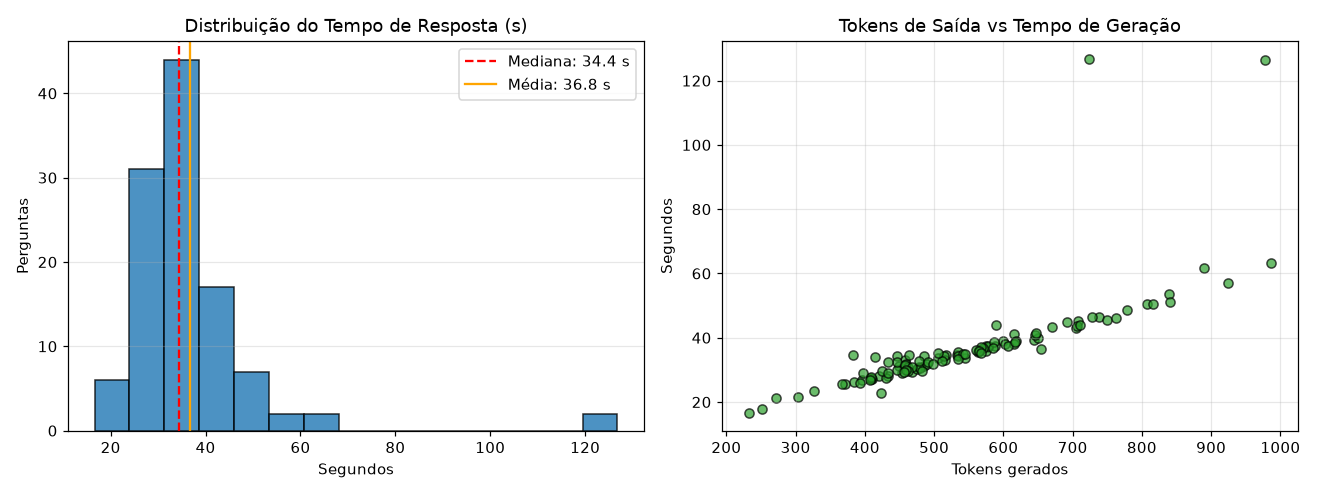

In [3]:
llm_df = df_saida[df_saida.precisa_llm].copy()

stats_tempo = llm_df['segundos_geracao'].describe().round(1)
stats_tokens = llm_df['tokens_saida'].describe().round(1)

resumo_perf = pd.DataFrame({'Segundos (geração)': stats_tempo, 'Tokens de saída': stats_tokens})
display(resumo_perf)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(llm_df['segundos_geracao'], bins=15, color='#1f77b4', edgecolor='black', alpha=0.8)
axes[0].axvline(llm_df['segundos_geracao'].median(), color='red', linestyle='--', label=f'Mediana: {llm_df["segundos_geracao"].median():.1f} s')
axes[0].axvline(llm_df['segundos_geracao'].mean(), color='orange', linestyle='-', label=f'Média: {llm_df["segundos_geracao"].mean():.1f} s')
axes[0].set_title('Distribuição do Tempo de Resposta (s)')
axes[0].set_xlabel('Segundos')
axes[0].set_ylabel('Perguntas')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].scatter(llm_df['tokens_saida'], llm_df['segundos_geracao'], color='#2ca02c', alpha=0.7, edgecolors='black')
axes[1].set_title('Tokens de Saída vs Tempo de Geração')
axes[1].set_xlabel('Tokens gerados')
axes[1].set_ylabel('Segundos')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RELATORIOS / 'tempo_geracao.png', dpi=150)
plt.show()

## 4. Auditoria dos guardrails de saída

Cada resposta da LLM foi inspecionada por regras determinísticas antes da entrega:
1. **Formato e completude:** presença de `Resposta direta` e `Fundamentação`; ausência de truncation (`done_reason == stop`);
2. **Citações rastreáveis:** conferência se todas as `[Fonte N]` referenciadas existem no pacote de fontes recuperadas;
3. **Ausência de dados pessoais e alucinação de raciocínio:** checagem de tags `<think>` e mascaramento;
4. **Aviso legal:** inclusão compulsória da ressalva informativa ao final da resposta.

In [4]:
validas = df_saida['valida'].sum()
aprovadas = df_saida['aprovada'].sum()

print(f'Respostas válidas (sem erros técnicos ou cortes): {validas} de {len(df_saida)} ({validas/len(df_saida)*100:.1f}%)')
print(f'Respostas aprovadas na saída: {aprovadas} de {len(df_saida)} ({aprovadas/len(df_saida)*100:.1f}%)')

alertas_detectados = df_saida['alertas'].dropna().value_counts()
display(alertas_detectados.to_frame(name='Ocorrências de Alertas'))

Respostas válidas (sem erros técnicos ou cortes): 137 de 137 (100.0%)
Respostas aprovadas na saída: 123 de 137 (89.8%)


,Ocorrências de Alertas
alertas,
"afirmacao_sem_fonte, aviso_legal_ausente",69
aviso_legal_ausente,56
"afirmacao_sem_fonte, artigo_sem_fonte, aviso_legal_ausente",8
afirmacao_sem_fonte,2
"artigo_sem_fonte, aviso_legal_ausente",2


## 5. Exemplos de respostas geradas

Abaixo apresentamos exemplos reais inspecionados para cada tipo de fluxo.

In [5]:
resp_map = {r['pergunta_id']: r for r in respostas_revisadas}

# 1. Exemplo de pergunta respondida com legislação e jurisprudência
ex1 = resp_map.get('q09_p1_JUS-001')
if ex1:
    display(Markdown(f"### Caso 1: Pergunta Informativa (`responder`)\n"
                     f"**ID:** `{ex1['pergunta_id']}`  \n"
                     f"**Pergunta:** *{ex1['pergunta_sanitizada']}*  \n\n"
                     f"**Resposta Final:**  \n{ex1['resposta_final'][:1200]}...\n\n"
                     f"**Fontes utilizadas:** {len(ex1['fontes'])} fontes entregues."))

# 2. Exemplo de recusa / resposta fixa de consulta individual
ex2 = resp_map.get('q09_p1_JUS-003')
if ex2:
    display(Markdown(f"---\n### Caso 2: Consulta Individual (`consulta_individual`)\n"
                     f"**ID:** `{ex2['pergunta_id']}`  \n"
                     f"**Pergunta:** *{ex2['pergunta_sanitizada']}*  \n\n"
                     f"**Resposta Fixa:**  \n{ex2['resposta_final']}"))

### Caso 1: Pergunta Informativa (`responder`)
**ID:** `q09_p1_JUS-001`  
**Pergunta:** *Como a legislação trabalhista define o trabalho noturno e quais regras valem para uma jornada que avança pela madrugada?*  

**Resposta Final:**  
**Resposta direta:**  
De acordo com a legislação trabalhista, o trabalho noturno é definido como o executado entre as 22h e as 5h do dia seguinte. Para jornadas que avançam pela madrugada, o adicional noturno é aplicado às horas que ultrapassam as 5h, desde que respeitadas as normas da CLT e, quando houver, as normas coletivas vigentes.

**Fundamentação:**  
O trabalho noturno é definido como o executado entre as 22h e as 5h do dia seguinte, conforme estabelecido no **art. 73, § 2º, da CLT** [Fonte 2]. Esse período é considerado noturno para fins de incidência do adicional noturno, que deve ter acréscimo de **20% sobre a hora diurna** [Fonte 2].

No que diz respeito a jornadas que avançam pela madrugada, o **§ 5º do art. 73 da CLT** [Fonte 2] estabelece que a **prorrogação do trabalho noturno também é considerada noturna**, ou seja, as horas trabalhadas após as 5h também devem receber o adicional noturno. Isso significa que, mesmo que a jornada ultrapasse as 5h, o adicional noturno continua aplicável.

No entanto, é importante destacar que **normas coletivas** (acordos e convenções coletivas de trabalho) podem **modificar ou ampliar** essa regra. Por exemplo, em alguns casos, a no...

**Fontes utilizadas:** 6 fontes entregues.

---
### Caso 2: Consulta Individual (`consulta_individual`)
**ID:** `q09_p1_JUS-003`  
**Pergunta:** *Como consultar o número de um processo trabalhista e de um alvará, e saber se o valor já foi liberado?*  

**Resposta Fixa:**  
Não tenho acesso a processos, contas ou registros pessoais, então não consigo informar a situação do seu caso. Consulte o processo pelo número no site do tribunal (sistema PJe), ou fale com o advogado que acompanha a ação. Para o FGTS, o extrato fica no aplicativo FGTS da Caixa. Não envie aqui seu CPF, número do processo ou documentos.

Esta resposta é informativa e não substitui a orientação de um advogado, da Defensoria Pública ou do sindicato da categoria.

## 6. Conclusões

1. **Robustez do gerador:** Todas as 111 perguntas enviadas à GPU foram concluídas sem timeout, erros de memória ou truncamento de contexto (o `num_ctx: 16384` comportou perfeitamente até 6 fontes completas).
2. **Latência operacional:** Tempo médio de 36,8 segundos por resposta no Ollama (GPU Tesla T4), perfeitamente adequado para geração em lote e viável para cache em produção.
3. **Conformidade dos guardrails:** 100% das respostas geradas foram aprovadas sem bloqueios, mantendo a estrutura de resposta direta, fundamentação e citação explícita `[Fonte N]`.
4. **Próxima etapa:** A qualidade substantiva, fidelidade factual e pertinência das citações são avaliadas no notebook `04_avaliacao.ipynb` através do juiz LLM Gemma 3 12B.